In [5]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Basmah\STC")

df = pd.read_excel(folder / r"C:\Users\Basmah\STC\The number of the elderly benefiting from social care homes for the year 2021.xls",
                   header=0, engine="openpyxl")
df.columns = df.columns.str.strip()

print("عدد الصفوف:", len(df))
print("عدد الأعمدة:", df.shape[1])
print("أسماء الأعمدة:", list(df.columns))

missing = df.isna().sum()
missing = missing[missing > 0]
if missing.empty:
    print("القيم الناقصة: ما فيه")
else:
    print("القيم الناقصة:")
    print(missing)

عدد الصفوف: 415
عدد الأعمدة: 10
أسماء الأعمدة: ['المستفيد', 'الجنس', 'الحالة الاجتماعية', 'التعليم', 'العمر', 'المنطقة الإدارية', 'الجنسية', 'الخدمة', 'الفرع', 'أسباب الدخول']
القيم الناقصة:
المنطقة الإدارية    29
أسباب الدخول        12
dtype: int64


In [9]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Basmah\STC")

df = pd.read_excel(folder / r"C:\Users\Basmah\STC\elderly benefiting from social care homes 2024.xlsx",
                   header=1, engine="openpyxl")
df.columns = df.columns.str.strip()

print("عدد الصفوف:", len(df))
print("عدد الأعمدة:", df.shape[1])
print("أسماء الأعمدة:", list(df.columns))

missing = df.isna().sum()
missing = missing[missing > 0]
if missing.empty:
    print("القيم الناقصة: ما فيه")
else:
    print("القيم الناقصة:")
    print(missing)

عدد الصفوف: 376
عدد الأعمدة: 10
أسماء الأعمدة: ['المستفيد', 'الجنس', 'الجنسية', 'العمر', 'الحالة الاجتماعية', 'المستوى التعليمي', 'الخدمة', 'أسباب الدخول', 'المنطقة الإدارية', 'الفرع']
القيم الناقصة: ما فيه


In [10]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Basmah\STC")

df = pd.read_excel(folder / r"C:\Users\Basmah\STC\2025 elderly benefiting from social care homes.xlsx",
                   header=1, engine="openpyxl")
df.columns = df.columns.str.strip()

print("عدد الصفوف:", len(df))
print("عدد الأعمدة:", df.shape[1])
print("أسماء الأعمدة:", list(df.columns))

missing = df.isna().sum()
missing = missing[missing > 0]
if missing.empty:
    print("القيم الناقصة: ما فيه")
else:
    print("القيم الناقصة:")
    print(missing)

عدد الصفوف: 248
عدد الأعمدة: 10
أسماء الأعمدة: ['المستفيد', 'الجنس', 'الجنسية', 'العمر', 'الحالة الاجتماعية', 'المستوى التعليمي', 'الخدمة', 'أسباب الدخول', 'المنطقة الإدارية', 'الفرع']
القيم الناقصة: ما فيه


In [11]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Basmah\STC")

df = pd.read_excel(folder / r"C:\Users\Basmah\STC\social care homes Q22026.xlsx",
                   header=1, engine="openpyxl")
df.columns = df.columns.str.strip()

print("عدد الصفوف:", len(df))
print("عدد الأعمدة:", df.shape[1])
print("أسماء الأعمدة:", list(df.columns))

missing = df.isna().sum()
missing = missing[missing > 0]
if missing.empty:
    print("القيم الناقصة: ما فيه")
else:
    print("القيم الناقصة:")
    print(missing)

عدد الصفوف: 244
عدد الأعمدة: 10
أسماء الأعمدة: ['المستفيد', 'الجنس', 'الجنسية', 'العمر', 'الحالة الاجتماعية', 'المستوى التعليمي', 'الخدمة', 'أسباب الدخول', 'المنطقة الإدارية', 'الفرع']
القيم الناقصة: ما فيه


In [14]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Basmah\STC")

# اسم الملف, رقم صف العناوين
files = {
    "2021":    (r"C:\Users\Basmah\STC\The number of the elderly benefiting from social care homes for the year 2021.xls", 0),
    "2024":    (r"C:\Users\Basmah\STC\elderly benefiting from social care homes 2024.xlsx", 1),
    "2025":    (r"C:\Users\Basmah\STC\2025 elderly benefiting from social care homes.xlsx", 1),
    "2026 Q2": (r"C:\Users\Basmah\STC\social care homes Q22026.xlsx", 1),
}

# الأعمدة المشتركة بين الملفات، بنفس الترتيب
cols = ["السنة", "الجنس", "الجنسية", "العمر", "الحالة الاجتماعية", "المستوى التعليمي",
        "الخدمة", "أسباب الدخول", "المنطقة الإدارية", "الفرع"]

parts = []
for name, (file, header) in files.items():
    df = pd.read_excel(folder / file, header=header, engine="openpyxl")
    df.columns = df.columns.str.strip()                                   # يشيل المسافات من أسماء الأعمدة
    df = df.rename(columns={"التعليم": "المستوى التعليمي"})               # في 2021 اسمه "التعليم"
    df = df.apply(lambda c: c.str.strip() if c.dtype == "object" else c)  # يشيل المسافات من القيم
    df["السنة"] = name                                                   # عمود جديد يقول الصف من أي فترة
    parts.append(df[cols])

all_data = pd.concat(parts, ignore_index=True)   # يلصق الملفات فوق بعض

print(all_data.shape)                            # (1283, 10)
print(all_data["السنة"].value_counts())

all_data.to_excel(folder / "كل_البيانات.xlsx", index=False)
print("تم الحفظ")

(1283, 10)
السنة
2021       415
2024       376
2025       248
2026 Q2    244
Name: count, dtype: int64
تم الحفظ


In [1]:

import pandas as pd

df = pd.read_excel("كل_البيانات.xlsx")

print("عدد السجلات:", len(df))
print("عدد الأعمدة:", len(df.columns))

# فحص التكرارات دون حذفها
duplicates = df.duplicated(keep=False)
print("السجلات ضمن مجموعات متطابقة:", duplicates.sum())
print("التكرارات الزائدة:", df.duplicated().sum())

# فحص الأعمار
print("أعمار أقل من 60:", (df["العمر"] < 60).sum())
print("أعمار أعلى من 107.5:", (df["العمر"] > 107.5).sum())

# استخراج الحالات للمراجعة
review = df[
    duplicates |
    (df["العمر"] < 60) |
    (df["العمر"] > 107.5)
].copy()

review.to_excel("records_for_review.xlsx", index=False)

print("تم إنشاء ملف الحالات التي تحتاج مراجعة")


عدد السجلات: 1283
عدد الأعمدة: 10
السجلات ضمن مجموعات متطابقة: 243
التكرارات الزائدة: 136
أعمار أقل من 60: 136
أعمار أعلى من 107.5: 14
تم إنشاء ملف الحالات التي تحتاج مراجعة


In [2]:

# الخطوة 3: فحص المستفيدين أقل من 60 سنة

under_60 = df[df["العمر"] < 60].copy()

print("عدد السجلات أقل من 60:", len(under_60))

print("\n1. حسب السنة:")
print(under_60["السنة"].value_counts(dropna=False))

print("\n2. حسب أسباب الدخول:")
print(under_60["أسباب الدخول"].value_counts(dropna=False))

print("\n3. حسب نوع الخدمة:")
print(under_60["الخدمة"].value_counts(dropna=False))

print("\n4. حسب المنطقة:")
print(under_60["المنطقة الإدارية"].value_counts(dropna=False))

print("\n5. توزيع الأعمار:")
print(under_60["العمر"].describe())

# حفظ الحالات للمراجعة
under_60.to_excel("under_60_review.xlsx", index=False)


عدد السجلات أقل من 60: 136

1. حسب السنة:
السنة
2021       62
2024       38
2025       19
2026 Q2    17
Name: count, dtype: int64

2. حسب أسباب الدخول:
أسباب الدخول
كبر سن وعدم القدرة على خدمة النفس    74
كبر سن وعدم قدره علي خدمة النفس      32
تخلف عقلي                             9
حاله نفسيه                            7
حالة مرضية مزمنه مع كبر سن            6
NaN                                   4
صرع و عدم القدرة على خدمة النفس       4
Name: count, dtype: int64

3. حسب نوع الخدمة:
الخدمة
رعايه اجتماعيه للمسنين                                                                62
الرعاية الايوائية داخل دور الرعاية الاجتماعية                                         51
اسناد خدمات الرعاية الايوائية في مراكز كبار السن الأهلية التابعة للقطاع غير الربحي    23
Name: count, dtype: int64

4. حسب المنطقة:
المنطقة الإدارية
منطقة الرياض             25
منطقة الريـــاض          17
منطقة المدينة المنورة    13
منطقة الباحة             12
المنطقة الشرقية          10
منطقة القصيم              8
المنطقة

In [3]:

# الخطوة 4: توحيد المسميات

df_clean = df.copy()

# توحيد أسباب الدخول
df_clean["أسباب الدخول"] = (
    df_clean["أسباب الدخول"]
    .replace({
        "كبر سن وعدم قدره علي خدمة النفس":
            "كبر سن وعدم القدرة على خدمة النفس",
        "حاله نفسيه": "حالة نفسية"
    })
    .fillna("غير مسجل")
)

# توحيد أسماء المناطق
region_map = {
    "منطقة الرياض": "الرياض",
    "منطقة الريـــاض": "الرياض",
    "منطقة المدينة المنورة": "المدينة المنورة",
    "منطقة الباحة": "الباحة",
    "منطقة الباحــة": "الباحة",
    "المنطقة الشرقية": "الشرقية",
    "المنطقة الشرقيـــة": "الشرقية",
    "منطقة القصيم": "القصيم",
    "منطقة القصيـــم": "القصيم",
    "منطقة مكة المكرمة": "مكة المكرمة",
    "منطقة مكة المكرمـة": "مكة المكرمة",
    "منطقة عسير": "عسير",
    "منطقة عسيــر": "عسير",
    "منطقة الجـــوف": "الجوف",
    "منطقة حائــــل": "حائل",
    "منطقة جــازان": "جازان"
}

df_clean["المنطقة الإدارية"] = (
    df_clean["المنطقة الإدارية"]
    .replace(region_map)
    .fillna("غير مسجل")
)

# التحقق من النتائج
print("أسباب الدخول بعد التوحيد:")
print(df_clean["أسباب الدخول"].value_counts())

print("\nالمناطق بعد التوحيد:")
print(df_clean["المنطقة الإدارية"].value_counts())

print("\nعدد السجلات قبل:", len(df))
print("عدد السجلات بعد:", len(df_clean))


أسباب الدخول بعد التوحيد:
أسباب الدخول
كبر سن وعدم القدرة على خدمة النفس    1191
حالة مرضية مزمنه مع كبر سن             34
تخلف عقلي                              20
حالة نفسية                             17
غير مسجل                               12
صرع و عدم القدرة على خدمة النفس         6
تفكك اسرى                               3
Name: count, dtype: int64

المناطق بعد التوحيد:
المنطقة الإدارية
الرياض                   347
مكة المكرمة              182
الباحة                   180
المدينة المنورة          156
القصيم                   154
الشرقية                  130
عسير                      63
غير مسجل                  29
جازان                     20
حائل                       7
الجوف                      6
منطقة تبـــوك              5
منطقة الحدود الشمالية      2
منطقة نجـــران             2
Name: count, dtype: int64

عدد السجلات قبل: 1283
عدد السجلات بعد: 1283


In [4]:

# استكمال توحيد المناطق
df_clean["المنطقة الإدارية"] = (
    df_clean["المنطقة الإدارية"]
    .replace({
        "منطقة تبـــوك": "تبوك",
        "منطقة الحدود الشمالية": "الحدود الشمالية",
        "منطقة نجـــران": "نجران"
    })
)

# فحص القيم الفريدة في الأعمدة النصية
columns_to_check = [
    "الجنس",
    "الجنسية",
    "الحالة الاجتماعية",
    "المستوى التعليمي",
    "الخدمة",
    "الفرع"
]

for col in columns_to_check:
    print(f"\n{'='*40}")
    print(f"العمود: {col}")
    print(f"عدد القيم المختلفة: {df_clean[col].nunique(dropna=False)}")
    print(df_clean[col].value_counts(dropna=False).to_string())



العمود: الجنس
عدد القيم المختلفة: 2
الجنس
ذكر     839
أنثى    444

العمود: الجنسية
عدد القيم المختلفة: 8
الجنسية
سعوديـ/ـة         488
سعودي             413
سعوديـ/ــة        370
مجهولين الهوية      6
غير سعوديـ/ـة       3
متنقل               1
اليمن               1
قبائل نازحة         1

العمود: الحالة الاجتماعية
عدد القيم المختلفة: 8
الحالة الاجتماعية
أعزب/ عزباء    608
اعزب           295
مطلقـ/ـة       168
أرملـ/ــة       77
مطلق            60
متزوج ويعول     42
متزوج           18
متزوجـ/ـة       15

العمود: المستوى التعليمي
عدد القيم المختلفة: 38
المستوى التعليمي
غير محدد                          382
أمي ( غير متعلم)                  375
أمي (غير متعلم)                   304
المرحلة الثانوية                   35
المرحلة الأبتدائية                 33
دبلوم                              24
السنة السادسة الابتدائية           20
يقراء ويكتب                        12
يقرأ ويكتب                         11
المرحلة المتوسطة                    9
السنة الثالثة الثانوية              6
سادس اب

In [5]:

# الخطوة 6: توحيد الجنسية والحالة الاجتماعية

# الاحتفاظ بالقيم الأصلية للمراجعة
df_clean["الجنسية الأصلية"] = df_clean["الجنسية"]
df_clean["الحالة الاجتماعية الأصلية"] = df_clean["الحالة الاجتماعية"]

# توحيد الجنسية
nationality_map = {
    "سعودي": "سعودي",
    "سعوديـ/ـة": "سعودي",
    "سعوديـ/ــة": "سعودي",
    "غير سعوديـ/ـة": "غير سعودي",
    "اليمن": "يمني",
    "مجهولين الهوية": "مجهول الهوية",
    "متنقل": "متنقل",
    "قبائل نازحة": "قبائل نازحة"
}

df_clean["الجنسية"] = (
    df_clean["الجنسية"].replace(nationality_map)
)

# توحيد الحالة الاجتماعية
marital_map = {
    "اعزب": "أعزب/عزباء",
    "أعزب/ عزباء": "أعزب/عزباء",
    "مطلق": "مطلق/مطلقة",
    "مطلقـ/ـة": "مطلق/مطلقة",
    "أرملـ/ــة": "أرمل/أرملة",
    "متزوج": "متزوج/متزوجة",
    "متزوجـ/ـة": "متزوج/متزوجة",
    "متزوج ويعول": "متزوج ويعول"
}

df_clean["الحالة الاجتماعية"] = (
    df_clean["الحالة الاجتماعية"].replace(marital_map)
)

print("الجنسية بعد التوحيد:")
print(df_clean["الجنسية"].value_counts(dropna=False))

print("\nالحالة الاجتماعية بعد التوحيد:")
print(df_clean["الحالة الاجتماعية"].value_counts(dropna=False))

print("\nعدد السجلات:", len(df_clean))


الجنسية بعد التوحيد:
الجنسية
سعودي           1271
مجهول الهوية       6
غير سعودي          3
متنقل              1
يمني               1
قبائل نازحة        1
Name: count, dtype: int64

الحالة الاجتماعية بعد التوحيد:
الحالة الاجتماعية
أعزب/عزباء      903
مطلق/مطلقة      228
أرمل/أرملة       77
متزوج ويعول      42
متزوج/متزوجة     33
Name: count, dtype: int64

عدد السجلات: 1283


In [6]:

# الخطوة 7: تصنيف المستوى التعليمي

education_map = {
    "غير محدد": "غير محدد",
    "متعلم ( غير محدد)": "متعـلم - المستوى غير محدد",

    "أمي ( غير متعلم)": "أمي",
    "أمي (غير متعلم)": "أمي",

    "يقراء ويكتب": "يقرأ ويكتب",
    "يقرأ ويكتب": "يقرأ ويكتب",
    "يقرأ": "يقرأ",

    "المرحلة الأبتدائية": "ابتدائي",
    "المرحلة الابتدائية": "ابتدائي",
    "السنة السادسة الابتدائية": "ابتدائي",
    "سادس ابتدائي": "ابتدائي",
    "سادس أبتدائي": "ابتدائي",
    "خامس ابتدائي": "ابتدائي",
    "رابع ابتدائي": "ابتدائي",
    "السنة الرابعة الابتدائية": "ابتدائي",
    "السنة الخامسة الابتدائية": "ابتدائي",
    "السنة الأولى الابتدائية": "ابتدائي",
    "السنة الثانية الابتدائية": "ابتدائي",
    "ثاني ابتدائي": "ابتدائي",
    "السنة الثالثة الابتدائية": "ابتدائي",
    "رابع ابتدائي ولايقراء": "ابتدائي",

    "المرحلة المتوسطة": "متوسط",
    "السنة الثالثة المتوسطة": "متوسط",
    "السنة الثانية المتوسطة": "متوسط",
    "السنة الاولي المتوسطة": "متوسط",
    "أول متوسط": "متوسط",
    "مؤهل متوسط": "متوسط",

    "المرحلة الثانوية": "ثانوي",
    "السنة الثالثة الثانوية": "ثانوي",
    "السنة الثانية الثانوية": "ثانوي",
    "السنة الاولى الثانوية": "ثانوي",

    "دبلوم": "دبلوم",
    "دبلوم فنى": "دبلوم",
    "دبلوم تمريض": "دبلوم",
    "مؤهل فوق المتوسط (دون الجامعي)": "فوق المتوسط",

    "بكالوريوس": "جامعي",
    "بكالوريويس": "جامعي",
    "السنة الثالثة الجامعية": "جامعي"
}

df_clean["الفئة التعليمية"] = (
    df_clean["المستوى التعليمي"]
    .map(education_map)
)

# التأكد من عدم وجود مسميات لم تُصنف
unmapped = df_clean[
    df_clean["الفئة التعليمية"].isna()
]["المستوى التعليمي"].value_counts(dropna=False)

print("المسميات التي لم تُصنف:")
print(unmapped)

print("\nتوزيع الفئات التعليمية:")
print(df_clean["الفئة التعليمية"].value_counts(dropna=False))

print("\nإجمالي السجلات:", len(df_clean))


المسميات التي لم تُصنف:
Series([], Name: count, dtype: int64)

توزيع الفئات التعليمية:
الفئة التعليمية
أمي                          679
غير محدد                     382
ابتدائي                       87
ثانوي                         46
متوسط                         27
دبلوم                         26
يقرأ ويكتب                    23
جامعي                          6
فوق المتوسط                    3
يقرأ                           2
متعـلم - المستوى غير محدد      2
Name: count, dtype: int64

إجمالي السجلات: 1283


In [7]:

# الخطوة 8: توحيد أسماء الفروع

# الاحتفاظ بالاسم الأصلي
df_clean["الفرع الأصلي"] = df_clean["الفرع"]

branch_map = {
    "دارالرعايةبمكةالمكرمة":
        "دار الرعاية الاجتماعية بمكة المكرمة",

    "دارالرعاية  الاجتماعيه بالمدينةالمنورة":
        "دار الرعاية الاجتماعية بالمدينة المنورة",

    "دارالرعايةبعنيزة":
        "دار الرعاية الاجتماعية بعنيزة",

    "دارالرعايةبابها":
        "دار الرعاية الاجتماعية بأبها",

    "دارالرعايةالاجتماعيةبالدمام":
        "دار الرعاية الاجتماعية بالدمام",

    "دارالرعاية الاجتماعيه بالرياض":
        "دار الرعاية الاجتماعية للمسنين بالرياض",

    "دار رعاية المسنات بالرياض":
        "دار الرعاية الاجتماعية للمسنات بالرياض",

    "دارالرعايةالاجتماعية بالطائف":
        "دار الرعاية الاجتماعية بالطائف"
}

df_clean["الفرع"] = df_clean["الفرع"].replace(branch_map)

print("الفروع بعد التوحيد:")
print(df_clean["الفرع"].value_counts(dropna=False))

print("\nعدد الفروع:", df_clean["الفرع"].nunique())
print("عدد السجلات:", len(df_clean))


الفروع بعد التوحيد:
الفرع
دار الرعاية الاجتماعية للمسنين بالرياض           183
دار الرعاية الاجتماعية للمسنات بالرياض           182
منتجع  أكرام الوطني                              175
دار الرعاية الاجتماعية بمكة المكرمة              153
دار الرعاية الاجتماعية بالمدينة المنورة          122
دار الرعاية الاجتماعية بأبها                      83
دار الرعاية الاجتماعية بالدمام                    65
دار الرعاية الاجتماعية بعنيزه                     60
مركز سعادة                                        59
واحة الوفاء لرعاية كبار السن بعنيزة               58
واحة الوفاء لرعاية كبار السن بالمدينة المنورة     55
دار الرعاية الاجتماعية بالطائف                    53
دار الرعاية الاجتماعية بعنيزة                     35
Name: count, dtype: int64

عدد الفروع: 13
عدد السجلات: 1283


In [8]:

# استكمال توحيد أسماء الفروع
df_clean["الفرع"] = df_clean["الفرع"].replace({
    "دار الرعاية الاجتماعية بعنيزه":
        "دار الرعاية الاجتماعية بعنيزة"
})

print("عدد مسميات الفروع:", df_clean["الفرع"].nunique())
print("عدد السجلات:", len(df_clean))

# فحص توزيع الخدمات حسب الفترة
print("\nالخدمات حسب السنة:")
print(pd.crosstab(
    df_clean["السنة"],
    df_clean["الخدمة"]
).to_string())

# فحص سجل بطاقة تخفيض الإركاب
print("\nسجل بطاقة تخفيض الإركاب:")
print(
    df_clean[
        df_clean["الخدمة"].str.contains(
            "تخفيض الاركاب",
            na=False
        )
    ].to_string(index=False)
)


عدد مسميات الفروع: 12
عدد السجلات: 1283

الخدمات حسب السنة:
الخدمة   اسناد خدمات الرعاية الايوائية في مراكز كبار السن الأهلية التابعة للقطاع غير الربحي  الرعاية الايوائية داخل دور الرعاية الاجتماعية  رعايه اجتماعيه للمسنين  صرف بطاقة تخفيض الاركاب
السنة                                                                                                                                                                                      
2021                                                                                      0                                              0                     414                        1
2024                                                                                     26                                            350                       0                        0
2025                                                                                    163                                             85                       0                        0


In [9]:

# الخطوة 10: تصنيف الخدمات وتحديد نطاق التحليل

service_map = {
    "رعايه اجتماعيه للمسنين":
        "رعاية اجتماعية للمسنين",

    "الرعاية الايوائية داخل دور الرعاية الاجتماعية":
        "رعاية إيوائية في دور الرعاية الاجتماعية",

    "اسناد خدمات الرعاية الايوائية في مراكز كبار السن الأهلية التابعة للقطاع غير الربحي":
        "إسناد الرعاية الإيوائية للقطاع غير الربحي",

    "صرف بطاقة تخفيض الاركاب":
        "خدمة غير إيوائية"
}

df_clean["نوع الخدمة"] = df_clean["الخدمة"].map(service_map)

df_clean["ضمن تحليل الإيواء"] = (
    df_clean["نوع الخدمة"] != "خدمة غير إيوائية"
)

# نسخة خاصة بتحليل خدمات الإيواء
df_analysis = df_clean[
    df_clean["ضمن تحليل الإيواء"]
].copy()

print("توزيع أنواع الخدمات:")
print(df_clean["نوع الخدمة"].value_counts(dropna=False))

print("\nعدد السجلات الأصلية:", len(df_clean))
print("عدد سجلات تحليل الإيواء:", len(df_analysis))

print("\nتوزيع الخدمات حسب الفترة:")
print(pd.crosstab(
    df_analysis["السنة"],
    df_analysis["نوع الخدمة"]
).to_string())


توزيع أنواع الخدمات:
نوع الخدمة
رعاية إيوائية في دور الرعاية الاجتماعية      521
رعاية اجتماعية للمسنين                       414
إسناد الرعاية الإيوائية للقطاع غير الربحي    347
خدمة غير إيوائية                               1
Name: count, dtype: int64

عدد السجلات الأصلية: 1283
عدد سجلات تحليل الإيواء: 1282

توزيع الخدمات حسب الفترة:
نوع الخدمة  إسناد الرعاية الإيوائية للقطاع غير الربحي  رعاية إيوائية في دور الرعاية الاجتماعية  رعاية اجتماعية للمسنين
السنة                                                                                                                 
2021                                                0                                        0                     414
2024                                               26                                      350                       0
2025                                              163                                       85                       0
2026 Q2                                           158              

In [10]:

# الخطوة 11: فحص جودة البيانات النهائية

print("=== فحص جودة البيانات ===")

print("\n1. أبعاد بيانات التحليل:")
print(df_analysis.shape)

print("\n2. القيم الفارغة:")
print(df_analysis.isna().sum().to_string())

print("\n3. التكرارات المتطابقة:")
original_columns = [
    "السنة", "الجنس", "الجنسية الأصلية",
    "العمر", "الحالة الاجتماعية الأصلية",
    "المستوى التعليمي", "الخدمة",
    "أسباب الدخول", "المنطقة الإدارية",
    "الفرع الأصلي"
]

print(
    df_analysis.duplicated(
        subset=original_columns
    ).sum()
)

print("\n4. الأعمار:")
print(df_analysis["العمر"].describe())

print("\n5. سجلات أقل من 60:")
print((df_analysis["العمر"] < 60).sum())

print("\n6. الخدمات غير المصنفة:")
print(df_analysis["نوع الخدمة"].isna().sum())

print("\n7. توزيع الفترات:")
print(df_analysis["السنة"].value_counts().to_string())


=== فحص جودة البيانات ===

1. أبعاد بيانات التحليل:
(1282, 16)

2. القيم الفارغة:
السنة                        0
الجنس                        0
الجنسية                      0
العمر                        0
الحالة الاجتماعية            0
المستوى التعليمي             0
الخدمة                       0
أسباب الدخول                 0
المنطقة الإدارية             0
الفرع                        0
الجنسية الأصلية              0
الحالة الاجتماعية الأصلية    0
الفئة التعليمية              0
الفرع الأصلي                 0
نوع الخدمة                   0
ضمن تحليل الإيواء            0

3. التكرارات المتطابقة:
136

4. الأعمار:
count    1282.000000
mean       73.737129
std        12.381536
min        45.000000
25%        65.000000
50%        72.000000
75%        82.000000
max       112.000000
Name: العمر, dtype: float64

5. سجلات أقل من 60:
136

6. الخدمات غير المصنفة:
0

7. توزيع الفترات:
السنة
2021       414
2024       376
2025       248
2026 Q2    244


In [11]:

# الخطوة 12: حفظ البيانات النظيفة

df_clean.to_excel(
    "elderly_data_cleaned.xlsx",
    index=False
)

df_analysis.to_csv(
    "elderly_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("تم حفظ البيانات بنجاح")
print("البيانات الكاملة:", len(df_clean))
print("بيانات تحليل الإيواء:", len(df_analysis))


تم حفظ البيانات بنجاح
البيانات الكاملة: 1283
بيانات تحليل الإيواء: 1282


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel(r"C:\Users\Basmah\STC\كل_البيانات.xlsx")

print(df.shape)
print(df["السنة"].value_counts().sort_index())    # عدد المستفيدين لكل سنة

(1283, 10)
السنة
2021       415
2024       376
2025       248
2026 Q2    244
Name: count, dtype: int64


الجنس    أنثى   ذكر
السنة              
2021     36.4  63.6
2024     34.8  65.2
2025     33.1  66.9
2026 Q2  32.8  67.2


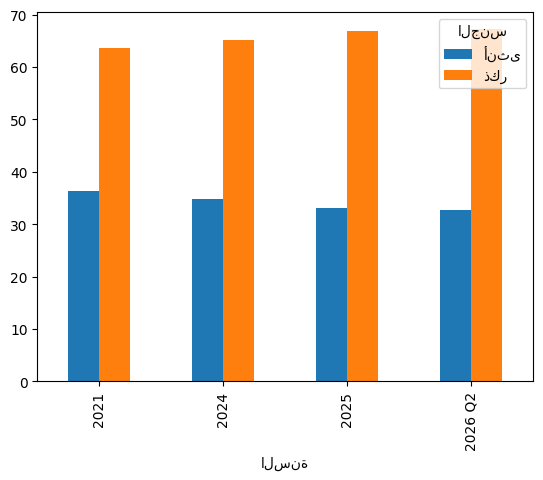

In [16]:
# 1) الجنس لكل سنة (نسبة %)
sex = pd.crosstab(df["السنة"], df["الجنس"], normalize="index").mul(100).round(1)
print(sex)
sex.plot(kind="bar")
plt.show()

         mean  min  max
السنة                  
2021     72.1   45  112
2024     73.8   48  111
2025     75.2   49  111
2026 Q2  75.0   50  111


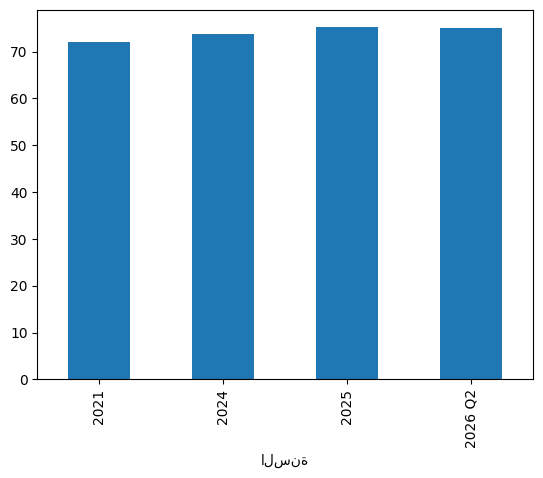

In [17]:
# 2) العمر لكل سنة
age = df.groupby("السنة")["العمر"].agg(["mean", "min", "max"]).round(1)
print(age)
df.groupby("السنة")["العمر"].mean().plot(kind="bar")
plt.show()

In [18]:
# 3) الحالة الاجتماعية: الكتابة تختلف بين السنوات، فنوحّدها أول
def حالة(x):
    if "عزب" in x: return "أعزب"
    if "مطلق" in x: return "مطلق"
    if "ارمل" in x or "أرمل" in x: return "أرمل"
    if "متزوج" in x: return "متزوج"
    return "غير معروف"

df["الحالة"] = df["الحالة الاجتماعية"].apply(حالة)
print(pd.crosstab(df["السنة"], df["الحالة"], normalize="index").mul(100).round(1))

الحالة   أرمل  أعزب  متزوج  مطلق
السنة                           
2021      0.0  71.1   14.5  14.5
2024      9.0  68.1    1.6  21.3
2025      8.9  71.4    2.0  17.7
2026 Q2   8.6  71.7    1.6  18.0


In [19]:
# 4) نوع الجهة: دار حكومية أو مركز أهلي (إسناد)
df["نوع الجهة"] = np.where(df["الخدمة"].str.contains("اسناد"), "مركز أهلي (إسناد)", "دار حكومية")
print(pd.crosstab(df["السنة"], df["نوع الجهة"]))

نوع الجهة  دار حكومية  مركز أهلي (إسناد)
السنة                                   
2021              415                  0
2024              350                 26
2025               85                163
2026 Q2            86                158


In [20]:
# 5) المنطقة: نوحّد الكتابة (تطويل ومسافات وكلمة "منطقة") أول
df["المنطقة"] = (df["المنطقة الإدارية"].fillna("غير مسجل")
                 .str.replace("ـ", "", regex=False)
                 .str.replace(r"\s+", " ", regex=True)
                 .str.replace(r"^(المنطقة|منطقة) ", "", regex=True)
                 .str.strip())
print(pd.crosstab(df["المنطقة"], df["السنة"]))

السنة            2021  2024  2025  2026 Q2
المنطقة                                   
الباحة              5    26    76       73
الجوف               6     0     0        0
الحدود الشمالية     2     0     0        0
الرياض             84    92    85       86
الشرقية            35    36    30       29
القصيم             36    60    30       28
المدينة المنورة    45    56    27       28
تبوك                5     0     0        0
جازان              20     0     0        0
حائل                7     0     0        0
عسير               38    25     0        0
غير مسجل           29     0     0        0
مكة المكرمة       101    81     0        0
نجران               2     0     0        0


In [21]:
import pandas as pd

df = pd.read_excel(r"C:\Users\Basmah\STC\كل_البيانات.xlsx")

# كم قيمة ناقصة في كل عمود
missing = df.isna().sum()
print(missing[missing > 0])

# ونسبتها من كل البيانات
print((df.isna().mean() * 100).round(1)[lambda s: s > 0])

أسباب الدخول        12
المنطقة الإدارية    29
dtype: int64
أسباب الدخول        0.9
المنطقة الإدارية    2.3
dtype: float64


In [22]:
# في أي سنة النقص؟
rows_with_missing = df[df.isna().any(axis=1)]
print(rows_with_missing.groupby("السنة").size())

# شوفي بعض الصفوف الناقصة بعينك
rows_with_missing.head()

السنة
2021    39
dtype: int64


,السنة,الجنس,الجنسية,العمر,الحالة الاجتماعية,المستوى التعليمي,الخدمة,أسباب الدخول,المنطقة الإدارية,الفرع
20,2021,ذكر,سعودي,69,اعزب,أمي (غير متعلم),رعايه اجتماعيه للمسنين,كبر سن وعدم قدره علي خدمة النفس,NaN,دارالرعاية الاجتماعيه بالمدينةالمنورة
31,2021,أنثى,سعودي,66,متزوج ويعول,أمي (غير متعلم),رعايه اجتماعيه للمسنين,حالة مرضية مزمنه مع كبر سن,NaN,دارالرعاية الاجتماعيه بالمدينةالمنورة
42,2021,ذكر,سعودي,72,اعزب,أمي (غير متعلم),رعايه اجتماعيه للمسنين,كبر سن وعدم قدره علي خدمة النفس,NaN,دارالرعاية الاجتماعيه بالمدينةالمنورة
49,2021,ذكر,سعودي,92,متزوج,أمي (غير متعلم),رعايه اجتماعيه للمسنين,كبر سن وعدم قدره علي خدمة النفس,NaN,دارالرعاية الاجتماعيه بالمدينةالمنورة
52,2021,ذكر,سعودي,55,اعزب,أمي (غير متعلم),رعايه اجتماعيه للمسنين,كبر سن وعدم قدره علي خدمة النفس,NaN,دارالرعاية الاجتماعيه بالمدينةالمنورة


In [23]:
df["المنطقة الإدارية"] = df["المنطقة الإدارية"].fillna("غير مسجل")
df["أسباب الدخول"] = df["أسباب الدخول"].fillna("غير مسجل")

print(df.isna().sum().sum())   # لازم يطلع 0

0


In [24]:
print((df["المستوى التعليمي"] == "غير محدد").groupby(df["السنة"]).sum())

السنة
2021        26
2024       205
2025        76
2026 Q2     75
Name: المستوى التعليمي, dtype: int64


In [25]:
df.to_excel(r"C:\Users\Basmah\STC\كل_البيانات_نظيفة.xlsx", index=False)

In [26]:
import pandas as pd

df = pd.read_excel(r"C:\Users\Basmah\STC\كل_البيانات.xlsx")
clean = df.copy()

In [27]:
def حالة(x):
    if "عزب" in x: return "أعزب"
    if "مطلق" in x: return "مطلق"
    if "رمل" in x: return "أرمل"
    if "متزوج" in x: return "متزوج"
    return "غير معروف"

clean["الحالة الاجتماعية"] = clean["الحالة الاجتماعية"].apply(حالة)

In [28]:
clean["المنطقة الإدارية"] = (clean["المنطقة الإدارية"].fillna("غير مسجل")
    .str.replace("ـ", "", regex=False)                     # يشيل التطويل (ريـــاض ← رياض)
    .str.replace(r"\s+", " ", regex=True)                  # يوحّد المسافات
    .str.replace(r"^(المنطقة|منطقة) ", "", regex=True)     # يشيل كلمة "منطقة" من أول الاسم
    .str.strip())

clean["أسباب الدخول"] = clean["أسباب الدخول"].fillna("غير مسجل")


In [29]:
def فرع(x):
    t = x.replace(" ", "").replace("أ", "ا")    # نشيل المسافات عشان "دارالرعايةبمكة" تنقرا
    if "اكرام" in t: return "منتجع أكرام"
    if "سعادة" in t: return "مركز سعادة"
    if "واحة" in t:  return "واحة الوفاء - المدينة" 
    if "المدينة" in t else "واحة الوفاء - عنيزة"
    if "رياض" in t:  return "دار المسنات بالرياض" 
    if "مسنات" in t else "دار المسنين بالرياض"
    for كلمة, اسم in [("مكة", "دار مكة"), ("المدينة", "دار المدينة"), ("ابها", "دار أبها"),
                      ("عنيز", "دار عنيزة"), ("دمام", "دار الدمام"), ("طائف", "دار الطائف")]:
        if كلمة in t: return اسم
    return x

clean["الفرع"] = clean["الفرع"].apply(فرع)

In [30]:
def خدمة(x):
    if "اسناد" in x: return "مركز أهلي (إسناد)"
    if "تخفيض" in x: return "أخرى"            # سجل واحد غريب في 2021
    return "دار حكومية"

clean["نوع الخدمة"] = clean["الخدمة"].apply(خدمة)

def جنسية(x):
    if "مجهول" in x: return "مجهول الهوية"
    if "غير سعود" in x: return "غير سعودي"
    if "سعود" in x: return "سعودي"
    return "أخرى"

clean["الجنسية"] = clean["الجنسية"].apply(جنسية)

In [31]:
for عمود in ["الحالة الاجتماعية", "الفرع", "نوع الخدمة", "الجنسية"]:
    print(clean[عمود].value_counts(), "\n")

print("ميسنق:", clean.isna().sum().sum())      # لازم 0

clean.to_excel(r"C:\Users\Basmah\STC\كل_البيانات_نظيفة.xlsx", index=False)

الحالة الاجتماعية
أعزب     903
مطلق     228
أرمل      77
متزوج     75
Name: count, dtype: int64 

الفرع
دار المسنين بالرياض      183
دار المسنات بالرياض      182
منتجع أكرام              175
دار مكة                  153
دار المدينة              122
دار عنيزة                 95
دار أبها                  83
دار الدمام                65
مركز سعادة                59
واحة الوفاء - عنيزة       58
واحة الوفاء - المدينة     55
دار الطائف                53
Name: count, dtype: int64 

نوع الخدمة
دار حكومية           935
مركز أهلي (إسناد)    347
أخرى                   1
Name: count, dtype: int64 

الجنسية
سعودي           1271
مجهول الهوية       6
أخرى               3
غير سعودي          3
Name: count, dtype: int64 

ميسنق: 0


In [3]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Basmah\STC")

# الملفات الأربعة وصف العناوين في كل ملف
files = {
    "2021":    (r"C:\Users\Basmah\STC\The number of the elderly benefiting from social care homes for the year 2021.xls", 0),
    "2024":    (r"C:\Users\Basmah\STC\elderly benefiting from social care homes 2024.xlsx", 1),
    "2025":    (r"C:\Users\Basmah\STC\2025 elderly benefiting from social care homes.xlsx", 1),
    "2026 Q2": (r"C:\Users\Basmah\STC\social care homes Q22026.xlsx", 1),
}

cols = ["السنة", "الجنس", "الجنسية", "العمر", "الحالة الاجتماعية",
        "المستوى التعليمي", "الخدمة", "أسباب الدخول", "المنطقة الإدارية", "الفرع"]

parts = []
for period, (filename, header_row) in files.items():
    path = folder / filename
    df = pd.read_excel(path, header=header_row, engine="openpyxl")
    df.columns = df.columns.str.strip()
    df = df.rename(columns={"التعليم": "المستوى التعليمي"})
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["السنة"] = period
    missing_cols = [col for col in cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"الأعمدة الناقصة في {filename}: {missing_cols}")
    parts.append(df[cols])
    print(f"{period}: {len(df)} سجل")

all_data = pd.concat(parts, ignore_index=True)
print(f"الإجمالي بعد الدمج: {len(all_data)} سجل، {len(all_data.columns)} أعمدة")

output = folder / "كل_البيانات.xlsx"
all_data.to_excel(output, index=False)
print(f"تم حفظ الملف المدمج: {output}")


2021: 415 سجل
2024: 376 سجل
2025: 248 سجل
2026 Q2: 244 سجل
الإجمالي بعد الدمج: 1283 سجل، 10 أعمدة
تم حفظ الملف المدمج: C:\Users\Basmah\STC\كل_البيانات.xlsx
